# <div align="center"><span style="color:red">HW 2</span></div>

# 1. Introduction to Convolutional Layers :

### 1.1 Load and visualize a few sample images.

In [132]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import numpy as np

In [133]:
# pytorch has many built-in datasets
data_path = "./data"
train_dataset = torchvision.datasets.CIFAR10(
    root = data_path,
    download = True,
    train = True
)

Files already downloaded and verified


In [134]:
test_dataset = torchvision.datasets.CIFAR10(
    root=data_path,
    download=True,
    train=False
)

Files already downloaded and verified


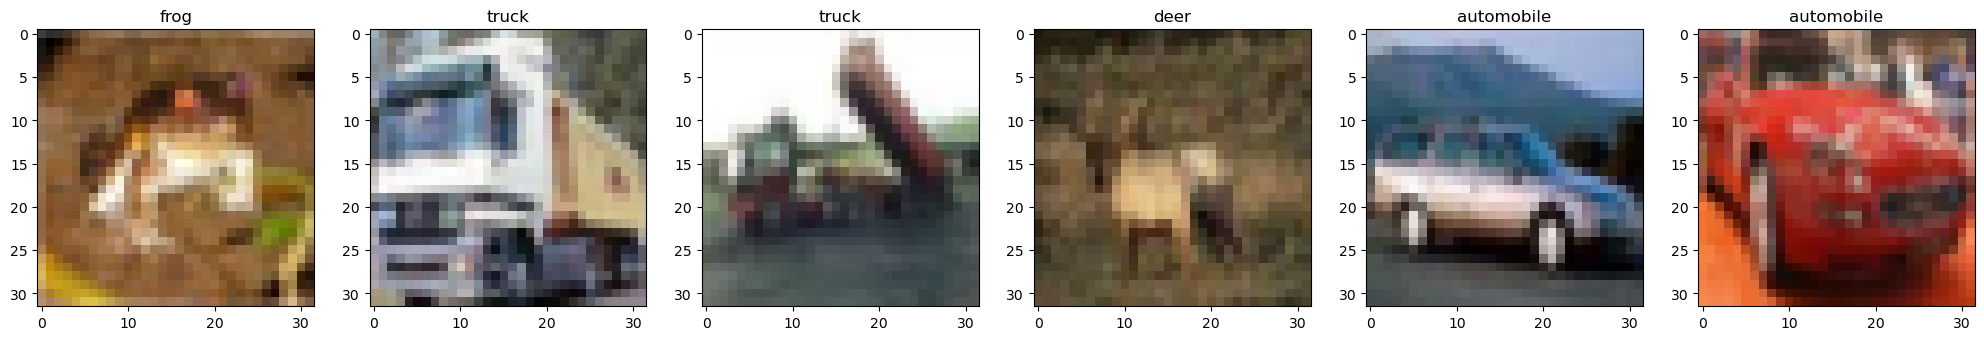

In [135]:
plt.figure(figsize=(25, 40))
for i in range(6):
    image, label = train_dataset[i]
    plt.subplot(1, 6, i + 1)
    plt.imshow(image)
    plt.title(train_dataset.classes[label])
plt.show()

### 1.2. Implement a single convolu􀆟onal layer using torch.nn.Conv2d.
* Use parameters:
    * Input channels: 3
    * Output channels: 8
    * Kernel size: 3
    * Padding: 1
* Pass one image through this layer.

In [136]:
experimental_model = nn.Conv2d(in_channels=3, out_channels=8, kernel_size=3, padding=1)
image , label = train_dataset[1]

transform = transforms.ToTensor()
image = transform(image)

with torch.no_grad():    
    image = experimental_model(image)

image.shape

torch.Size([8, 32, 32])

### 1.3. Visualize the feature maps (output of the convolution) using matplotlib.

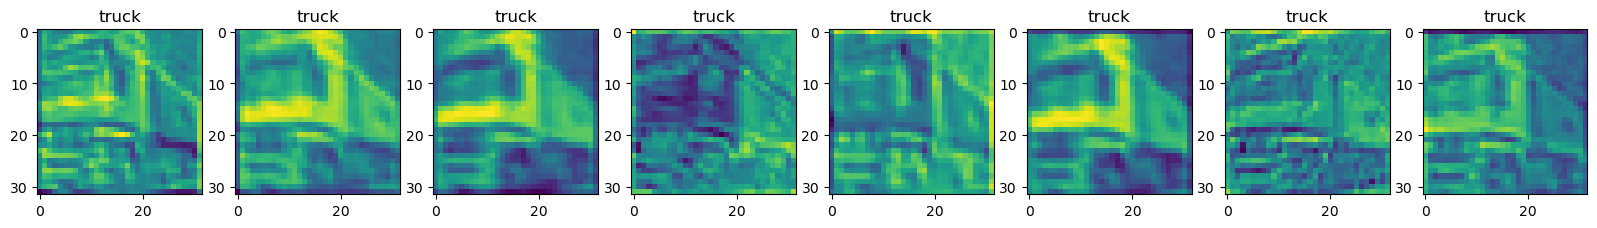

In [137]:
plt.figure(figsize=(20, 10))
for i in range(8):
    plt.subplot(1, 8, i + 1)
    plt.imshow(image[i].numpy())
    plt.title(train_dataset.classes[label])
plt.show()

# 2. Building a Simple CNN :

In [138]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [139]:
train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ToTensor()
])

test_transform = transforms.Compose([
    transforms.ToTensor()
])

In [140]:
# pytorch has many built-in datasets
data_path = "./data"
train_dataset = torchvision.datasets.CIFAR10(
    root = data_path,
    download = True,
    train = True, 
    transform=train_transform
)

Files already downloaded and verified


In [141]:
test_dataset = torchvision.datasets.CIFAR10(
    root=data_path,
    download=True,
    train=False, 
    transform=test_transform
)

Files already downloaded and verified


In [142]:
batch_size = 128
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

### 2.1. Implement a CNN from scratch using torch.nn:

In [143]:
class SimpleCNN(nn.Module):
    def __init__(self, num_classses):
        super(SimpleCNN, self).__init__()

        activation_function = nn.ReLU()

        # layer 1
        self.conv1 = nn.Conv2d(in_channels=3, out_channels=32, kernel_size=3, padding=1)
        #self.norm1 = nn.BatchNorm2d(32)
        self.relu1 = activation_function
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2)

        # layer2
        self.conv2 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1)
        #self.norm2 = nn.BatchNorm2d(64)
        self.relu2 = activation_function
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2)

        # layer3
        self.conv3 = nn.Conv2d(in_channels=64, out_channels=128, kernel_size=3, padding=1)
        #self.norm3 = nn.BatchNorm2d(128)
        self.relu3 = activation_function
        self.pool3 = nn.MaxPool2d(kernel_size=2, stride=2)

        self.flatten = nn.Flatten()

        # FullyConnecteds
        self.fc1 = nn.Linear(128 * 4 * 4, 512)
        self.relu4 = activation_function
        self.dropout = nn.Dropout(0.5)
        self.fc2 = nn.Linear(512, num_classses)

    def forward(self, x):
        x = self.conv1(x)
        #x = self.norm1(x)
        x = self.relu1(x)
        x = self.pool1(x)
        
        x = self.conv2(x)
        #x = self.norm2(x)
        x = self.relu2(x)
        x = self.pool2(x)

        x = self.conv3(x)
        #x = self.norm3(x)
        x = self.relu3(x)
        x = self.pool3(x)

        x = self.flatten(x)

        x = self.fc1(x)
        x = self.relu4(x)
        x = self.dropout(x)
        x = self.fc2(x)

        return x

### 2.2. Print the number of trainable parameters in the model.

In [144]:
model = SimpleCNN(10)
print(sum(p.numel() for p in model.parameters() if p.requires_grad))

1147466


### 2.3. Forward one batch of images through the model and verify output dimensions.

In [145]:
for images, labels in train_loader:
    with torch.no_grad():
        images = model(images)
    print(images.shape)
    break

torch.Size([128, 10])


# 3. Model Training :

### 3.1. Train the CNN for 10–15 epochs using:
* CrossEntropyLoss
* Adam optimizer
* Batch size = 128

In [146]:
def training_loop(model, train_loader, val_loader, loss_function, optimizer, num_epochs, device):
    model.to(device)
    train_loss = []
    train_accuracy = []
    val_loss = []
    val_accuracy = []

    print("--- Training Started ---")

    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0
        correct = 0
        total = len(train_loader.dataset)
        
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = loss_function(outputs, labels)
            loss.backward()
            optimizer.step()
            
            running_loss += loss.item() * labels.size(0)

            _, predicted = outputs.max(1)
            correct += predicted.eq(labels).sum().item()
        
        train_loss.append(running_loss / len(train_loader.dataset))
        train_accuracy.append(100 * correct / total)

        model.eval()
        running_loss = 0.0
        correct = 0
        total = len(val_loader.dataset)

        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)

                outputs = model(images)
                loss = loss_function(outputs, labels)

                running_loss += loss.item() * labels.size(0)

                _, predicted = outputs.max(1)
                correct += predicted.eq(labels).sum().item()

            val_loss.append(running_loss / total)
            val_accuracy.append(100 * correct / total)

            print(f"Epoch [{epoch+1}/{num_epochs}], Train Loss: {train_loss[epoch]:.4f}, Val Loss: {val_loss[epoch]:.4f}, train Accuracy: {train_accuracy[epoch]:.2f}%, Val Accuracy: {val_accuracy[epoch]:.2f}%")

        #if epoch >= 2:
        #    if val_accuracy[epoch] < val_accuracy[epoch - 1] and val_accuracy[epoch - 1] < val_accuracy[epoch - 2]:
        #        print("--- Finished Training ---")
        #        break

    print("--- Finished Training ---")

    metrics = [train_loss, val_loss, train_accuracy, val_accuracy]

    return model, metrics

In [147]:
loss_function = nn.CrossEntropyLoss()
model = SimpleCNN(10)
optimizer = optim.Adam(model.parameters(), lr=0.001)

In [148]:
trained_model, training_metrics = training_loop(
    model=model,
    train_loader=train_loader,
    val_loader=test_loader,
    loss_function=loss_function, 
    optimizer=optimizer, 
    num_epochs=25,
    device=device
)

--- Training Started ---
Epoch [1/25], Train Loss: 1.6579, Val Loss: 1.3418, train Accuracy: 38.83%, Val Accuracy: 50.59%
Epoch [2/25], Train Loss: 1.3187, Val Loss: 1.2395, train Accuracy: 52.43%, Val Accuracy: 56.26%
Epoch [3/25], Train Loss: 1.1740, Val Loss: 1.0224, train Accuracy: 58.09%, Val Accuracy: 63.74%
Epoch [4/25], Train Loss: 1.0677, Val Loss: 0.9703, train Accuracy: 61.89%, Val Accuracy: 65.38%
Epoch [5/25], Train Loss: 0.9851, Val Loss: 0.9015, train Accuracy: 65.14%, Val Accuracy: 68.34%
Epoch [6/25], Train Loss: 0.9247, Val Loss: 0.8264, train Accuracy: 67.40%, Val Accuracy: 70.83%
Epoch [7/25], Train Loss: 0.8717, Val Loss: 0.7836, train Accuracy: 69.24%, Val Accuracy: 72.39%
Epoch [8/25], Train Loss: 0.8394, Val Loss: 0.7669, train Accuracy: 70.55%, Val Accuracy: 73.16%
Epoch [9/25], Train Loss: 0.7993, Val Loss: 0.7520, train Accuracy: 72.02%, Val Accuracy: 73.99%
Epoch [10/25], Train Loss: 0.7732, Val Loss: 0.7389, train Accuracy: 72.95%, Val Accuracy: 73.91%
Epoc

### 3.2. Record and plot:
* Training vs validation loss
* Training vs validation accuracy

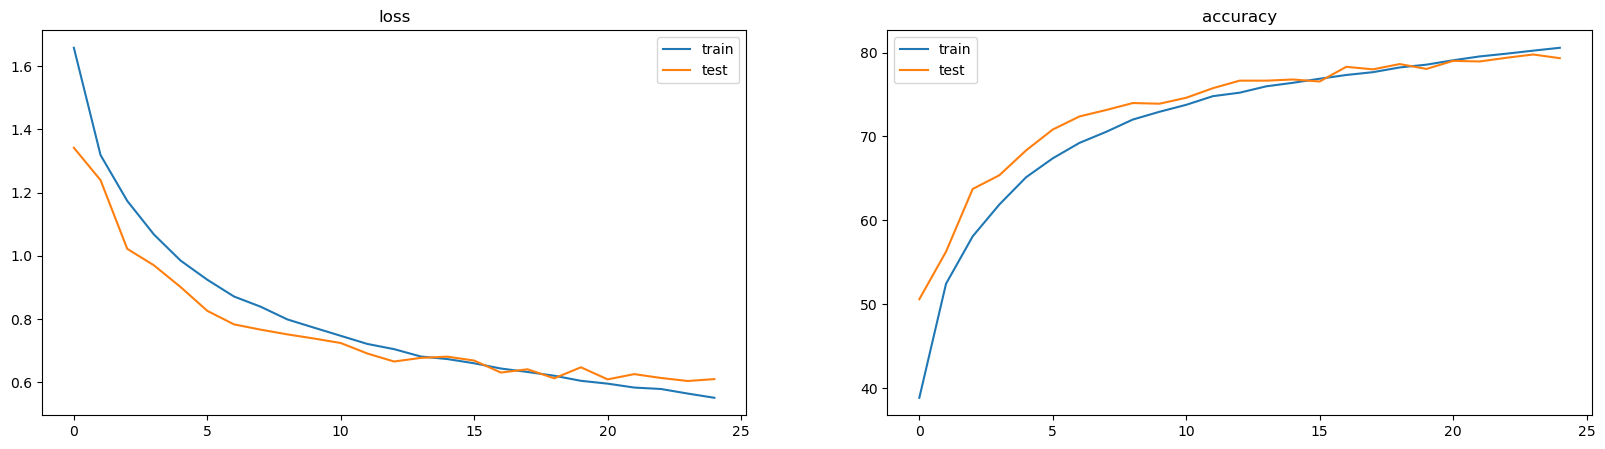

In [149]:
num_epochs = 25
plt.figure(figsize=(20,5))
plt.subplot(1, 2, 1)
plt.plot(range(num_epochs), training_metrics[0], label="train")
plt.plot(range(num_epochs), training_metrics[1], label="test")
plt.title("loss")
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(range(num_epochs), training_metrics[2], label="train")
plt.plot(range(num_epochs), training_metrics[3], label="test")
plt.title("accuracy")
plt.legend()
plt.show()

# 5. Overfitting and Regularization:

### 5.1. Train your CNN on a small subset of the training data (e.g., 2000 samples).

In [150]:
from torch.utils.data import Subset
small_dataset = Subset(train_dataset, list(range(2000)))
small_train_loader = DataLoader(small_dataset, batch_size=128, shuffle=True)

In [151]:
loss_function = nn.CrossEntropyLoss()
model = SimpleCNN(10)
optimizer = optim.Adam(model.parameters(), lr=0.001)

In [152]:
small_trained_model, small_training_metrics = training_loop(
    model=model,
    train_loader=small_train_loader,
    val_loader=test_loader,
    loss_function=loss_function, 
    optimizer=optimizer, 
    num_epochs=25,
    device=device
)

--- Training Started ---
Epoch [1/25], Train Loss: 2.2847, Val Loss: 2.1971, train Accuracy: 13.15%, Val Accuracy: 21.53%
Epoch [2/25], Train Loss: 2.1023, Val Loss: 2.0212, train Accuracy: 21.55%, Val Accuracy: 24.81%
Epoch [3/25], Train Loss: 2.0016, Val Loss: 1.9259, train Accuracy: 26.75%, Val Accuracy: 29.94%
Epoch [4/25], Train Loss: 1.9117, Val Loss: 1.8445, train Accuracy: 28.55%, Val Accuracy: 33.61%
Epoch [5/25], Train Loss: 1.8074, Val Loss: 1.7598, train Accuracy: 30.90%, Val Accuracy: 36.16%
Epoch [6/25], Train Loss: 1.7236, Val Loss: 1.7373, train Accuracy: 35.50%, Val Accuracy: 36.30%
Epoch [7/25], Train Loss: 1.6853, Val Loss: 1.7353, train Accuracy: 37.40%, Val Accuracy: 36.90%
Epoch [8/25], Train Loss: 1.6731, Val Loss: 1.6877, train Accuracy: 38.65%, Val Accuracy: 38.11%
Epoch [9/25], Train Loss: 1.6067, Val Loss: 1.5906, train Accuracy: 40.10%, Val Accuracy: 40.85%
Epoch [10/25], Train Loss: 1.5553, Val Loss: 1.5806, train Accuracy: 42.45%, Val Accuracy: 42.32%
Epoc

### 5.2. Plot training vs validation accuracy and demonstrate overfitting.

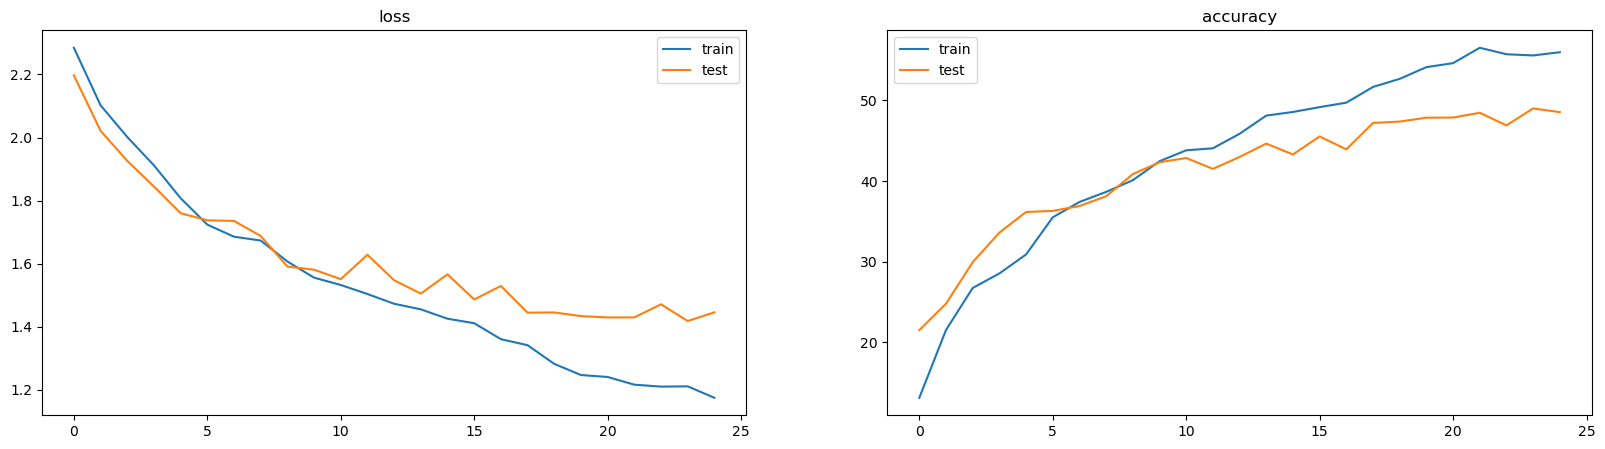

In [155]:
num_epochs = 25
plt.figure(figsize=(20,5))
plt.subplot(1, 2, 1)
plt.plot(range(num_epochs), small_training_metrics[0], label="train")
plt.plot(range(num_epochs), small_training_metrics[1], label="test")
plt.title("loss")
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(range(num_epochs), small_training_metrics[2], label="train")
plt.plot(range(num_epochs), small_training_metrics[3], label="test")
plt.title("accuracy")
plt.legend()
plt.show()

### 5.3. Apply techniques to reduce overfi􀆫ng:
* Dropout
* Data augmentation (using torchvision.transforms)
* Early stopping

i have added lines of codes to the earlier cells and commented them. i will uncomment them and run the 5.2 and 5.1 sections again and write the result in the documentation.

# 6. Model Evaluation:

airplane : 83.70%
automobile : 82.90%
bird : 70.00%
cat : 71.60%
deer : 79.40%
dog : 57.00%
frog : 83.40%
horse : 80.00%
ship : 89.50%
truck : 90.00%

 
 onfusion matrix : 
 tensor([[837.,   7.,  24.,  19.,   9.,   2.,   6.,  10.,  48.,  38.],
        [ 17., 829.,   1.,   8.,   2.,   2.,   4.,   1.,  24., 112.],
        [ 68.,   4., 700.,  60.,  71.,  26.,  31.,  21.,  10.,   9.],
        [ 19.,   4.,  51., 716.,  67.,  61.,  33.,  17.,  13.,  19.],
        [ 17.,   2.,  47.,  68., 794.,  10.,  24.,  25.,  11.,   2.],
        [ 14.,   0.,  47., 264.,  49., 570.,  12.,  32.,   6.,   6.],
        [  7.,   1.,  44.,  69.,  24.,   6., 834.,   3.,   5.,   7.],
        [ 13.,   0.,  25.,  54.,  70.,  25.,   1., 800.,   2.,  10.],
        [ 41.,  10.,   5.,  15.,   2.,   3.,   2.,   3., 895.,  24.],
        [ 26.,  29.,   5.,  15.,   3.,   1.,   3.,   3.,  15., 900.]])

 



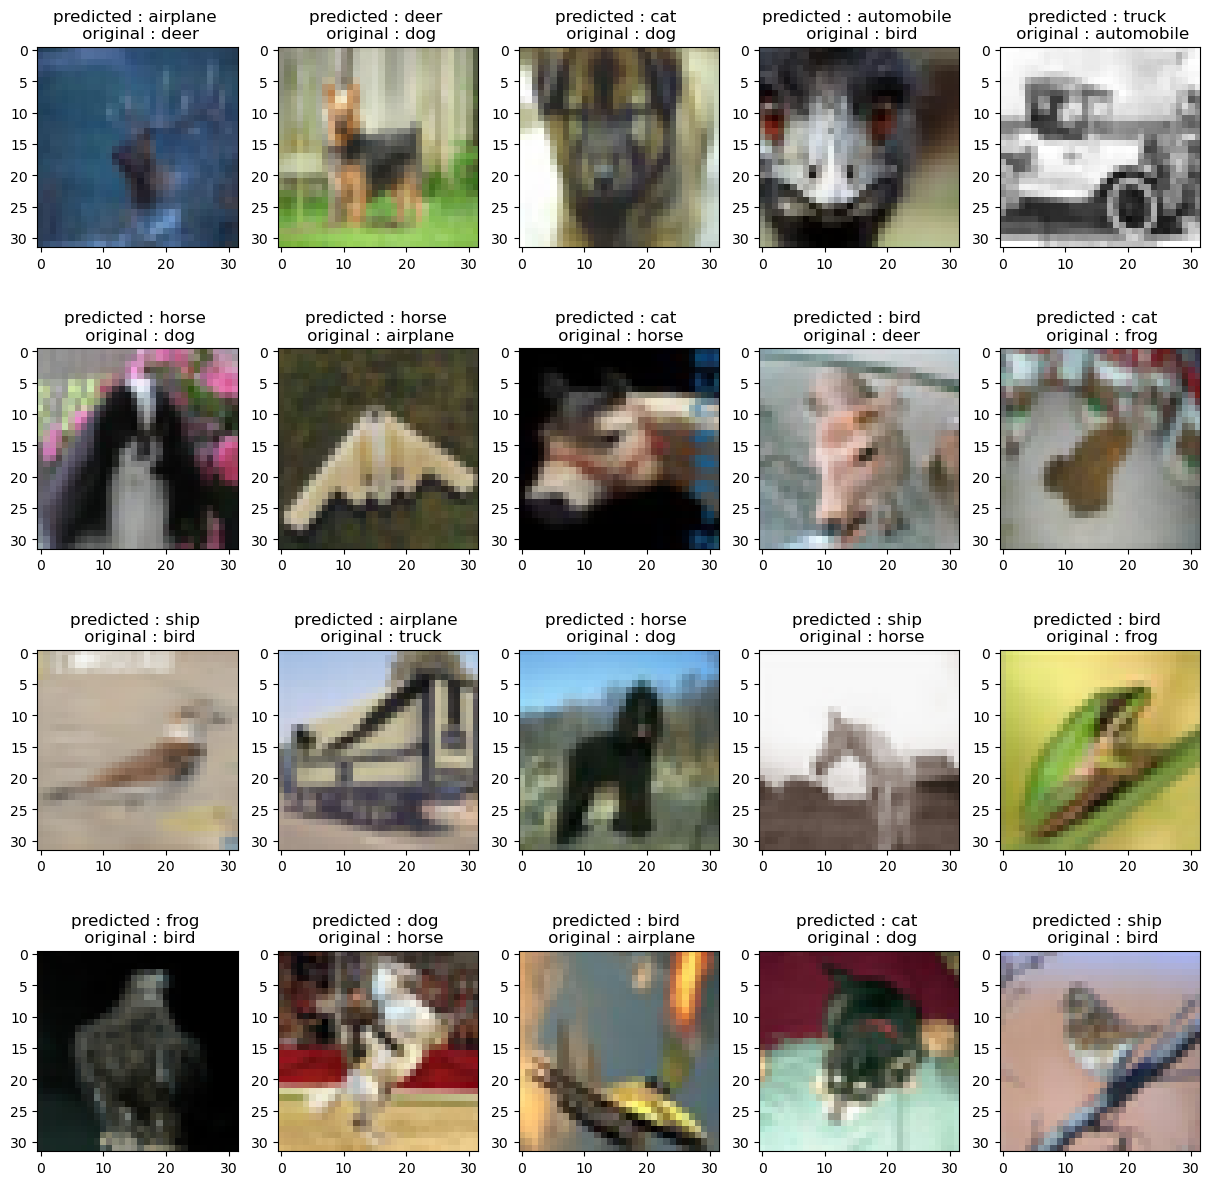

In [ ]:
classes = train_dataset.classes
num_classes = len(classes)
num_missclassified = 0

correct = np.zeros(num_classes)
total = np.zeros(num_classes)
cm = torch.zeros(num_classes, num_classes)
plt.figure(figsize=(15, 15))

model.eval()
with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, predicted = outputs.max(1)

        #confusion matrix
        for t, p in zip(labels, predicted):
            cm[t, p] += 1

        # update per-class counts
        for i in range(len(labels)):
            label = labels[i].item()
            total[label] += 1
            if predicted[i].item() == label:
                correct[label] += 1
            elif num_missclassified < 20:
                plt.subplot(4, 5, num_missclassified + 1)
                plt.imshow(images[i].cpu().permute(1, 2, 0).numpy())
                plt.title(f"predicted : {classes[predicted[i]]} \n original : {classes[labels[i]]}")
                num_missclassified += 1

# compute accuracy
per_class_accuracy = correct / total

for i in range(num_classes):
    print(f"{classes[i]} : {per_class_accuracy[i] * 100:.2f}%")

print("\n \n onfusion matrix : \n",cm)
print("\n \n")
plt.show()

# 7. Visualization and Understanding CNNs:

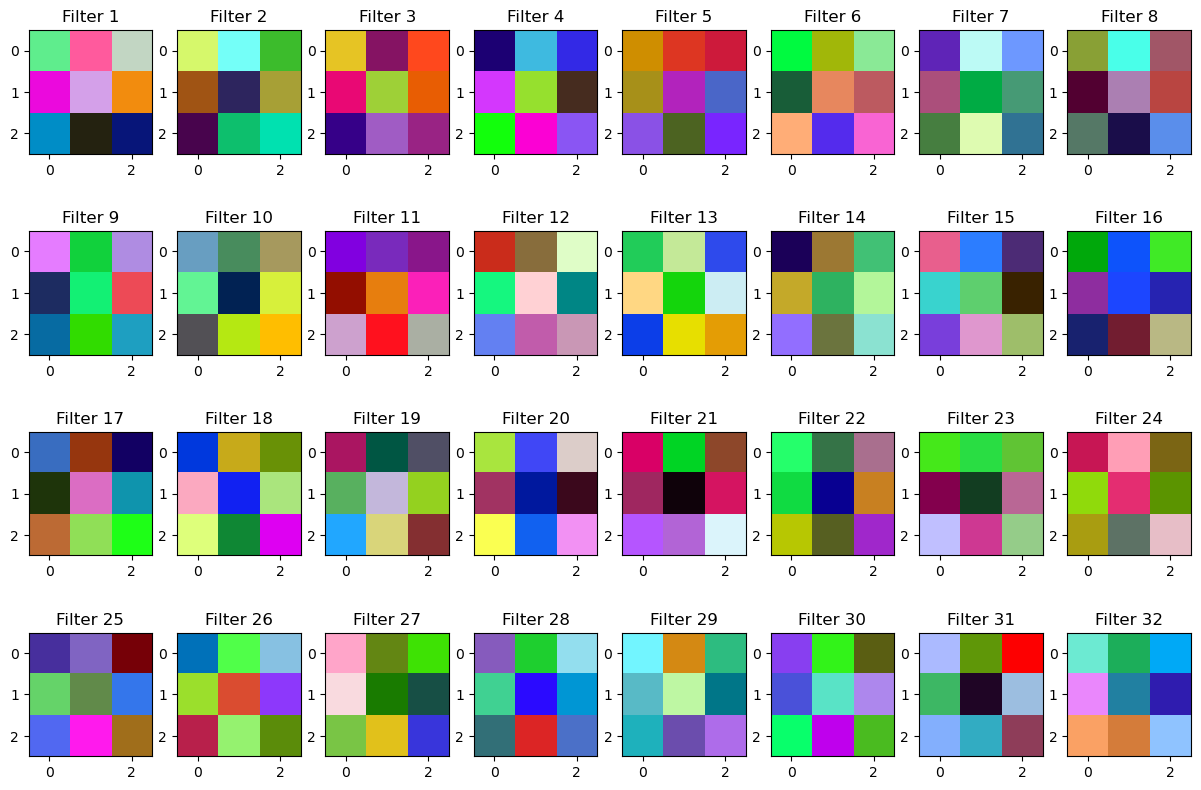

In [154]:
weights = model.conv1.weight.data.cpu()

plt.figure(figsize=(15, 10))

for i in range(32):
    f = weights[i]       

    f_min, f_max = f.min(), f.max()
    f = (f - f_min) / (f_max - f_min)

    f = f.permute(1, 2, 0).numpy()   # CHW -> HWC (RGB)

    plt.subplot(4, 8, i + 1)
    plt.imshow(f)
    plt.title(f"Filter {i + 1}")

plt.show()


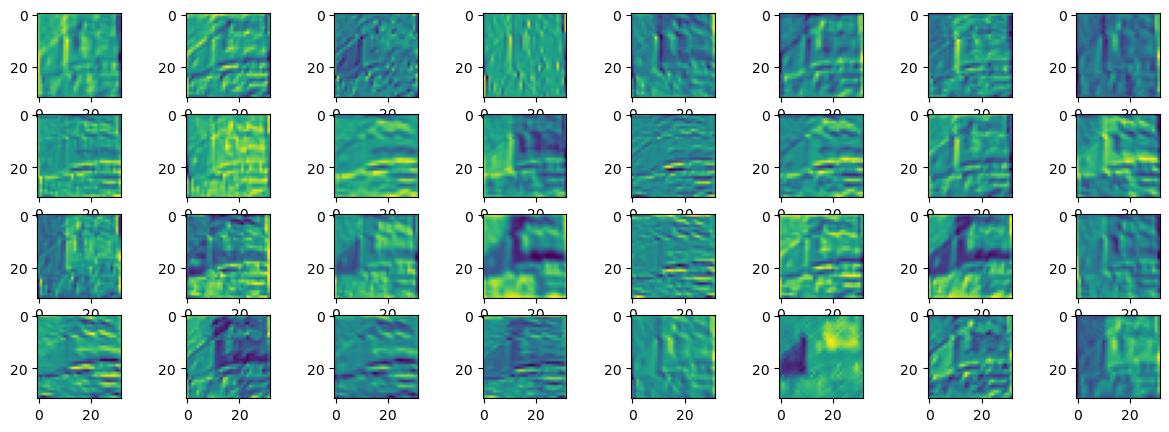

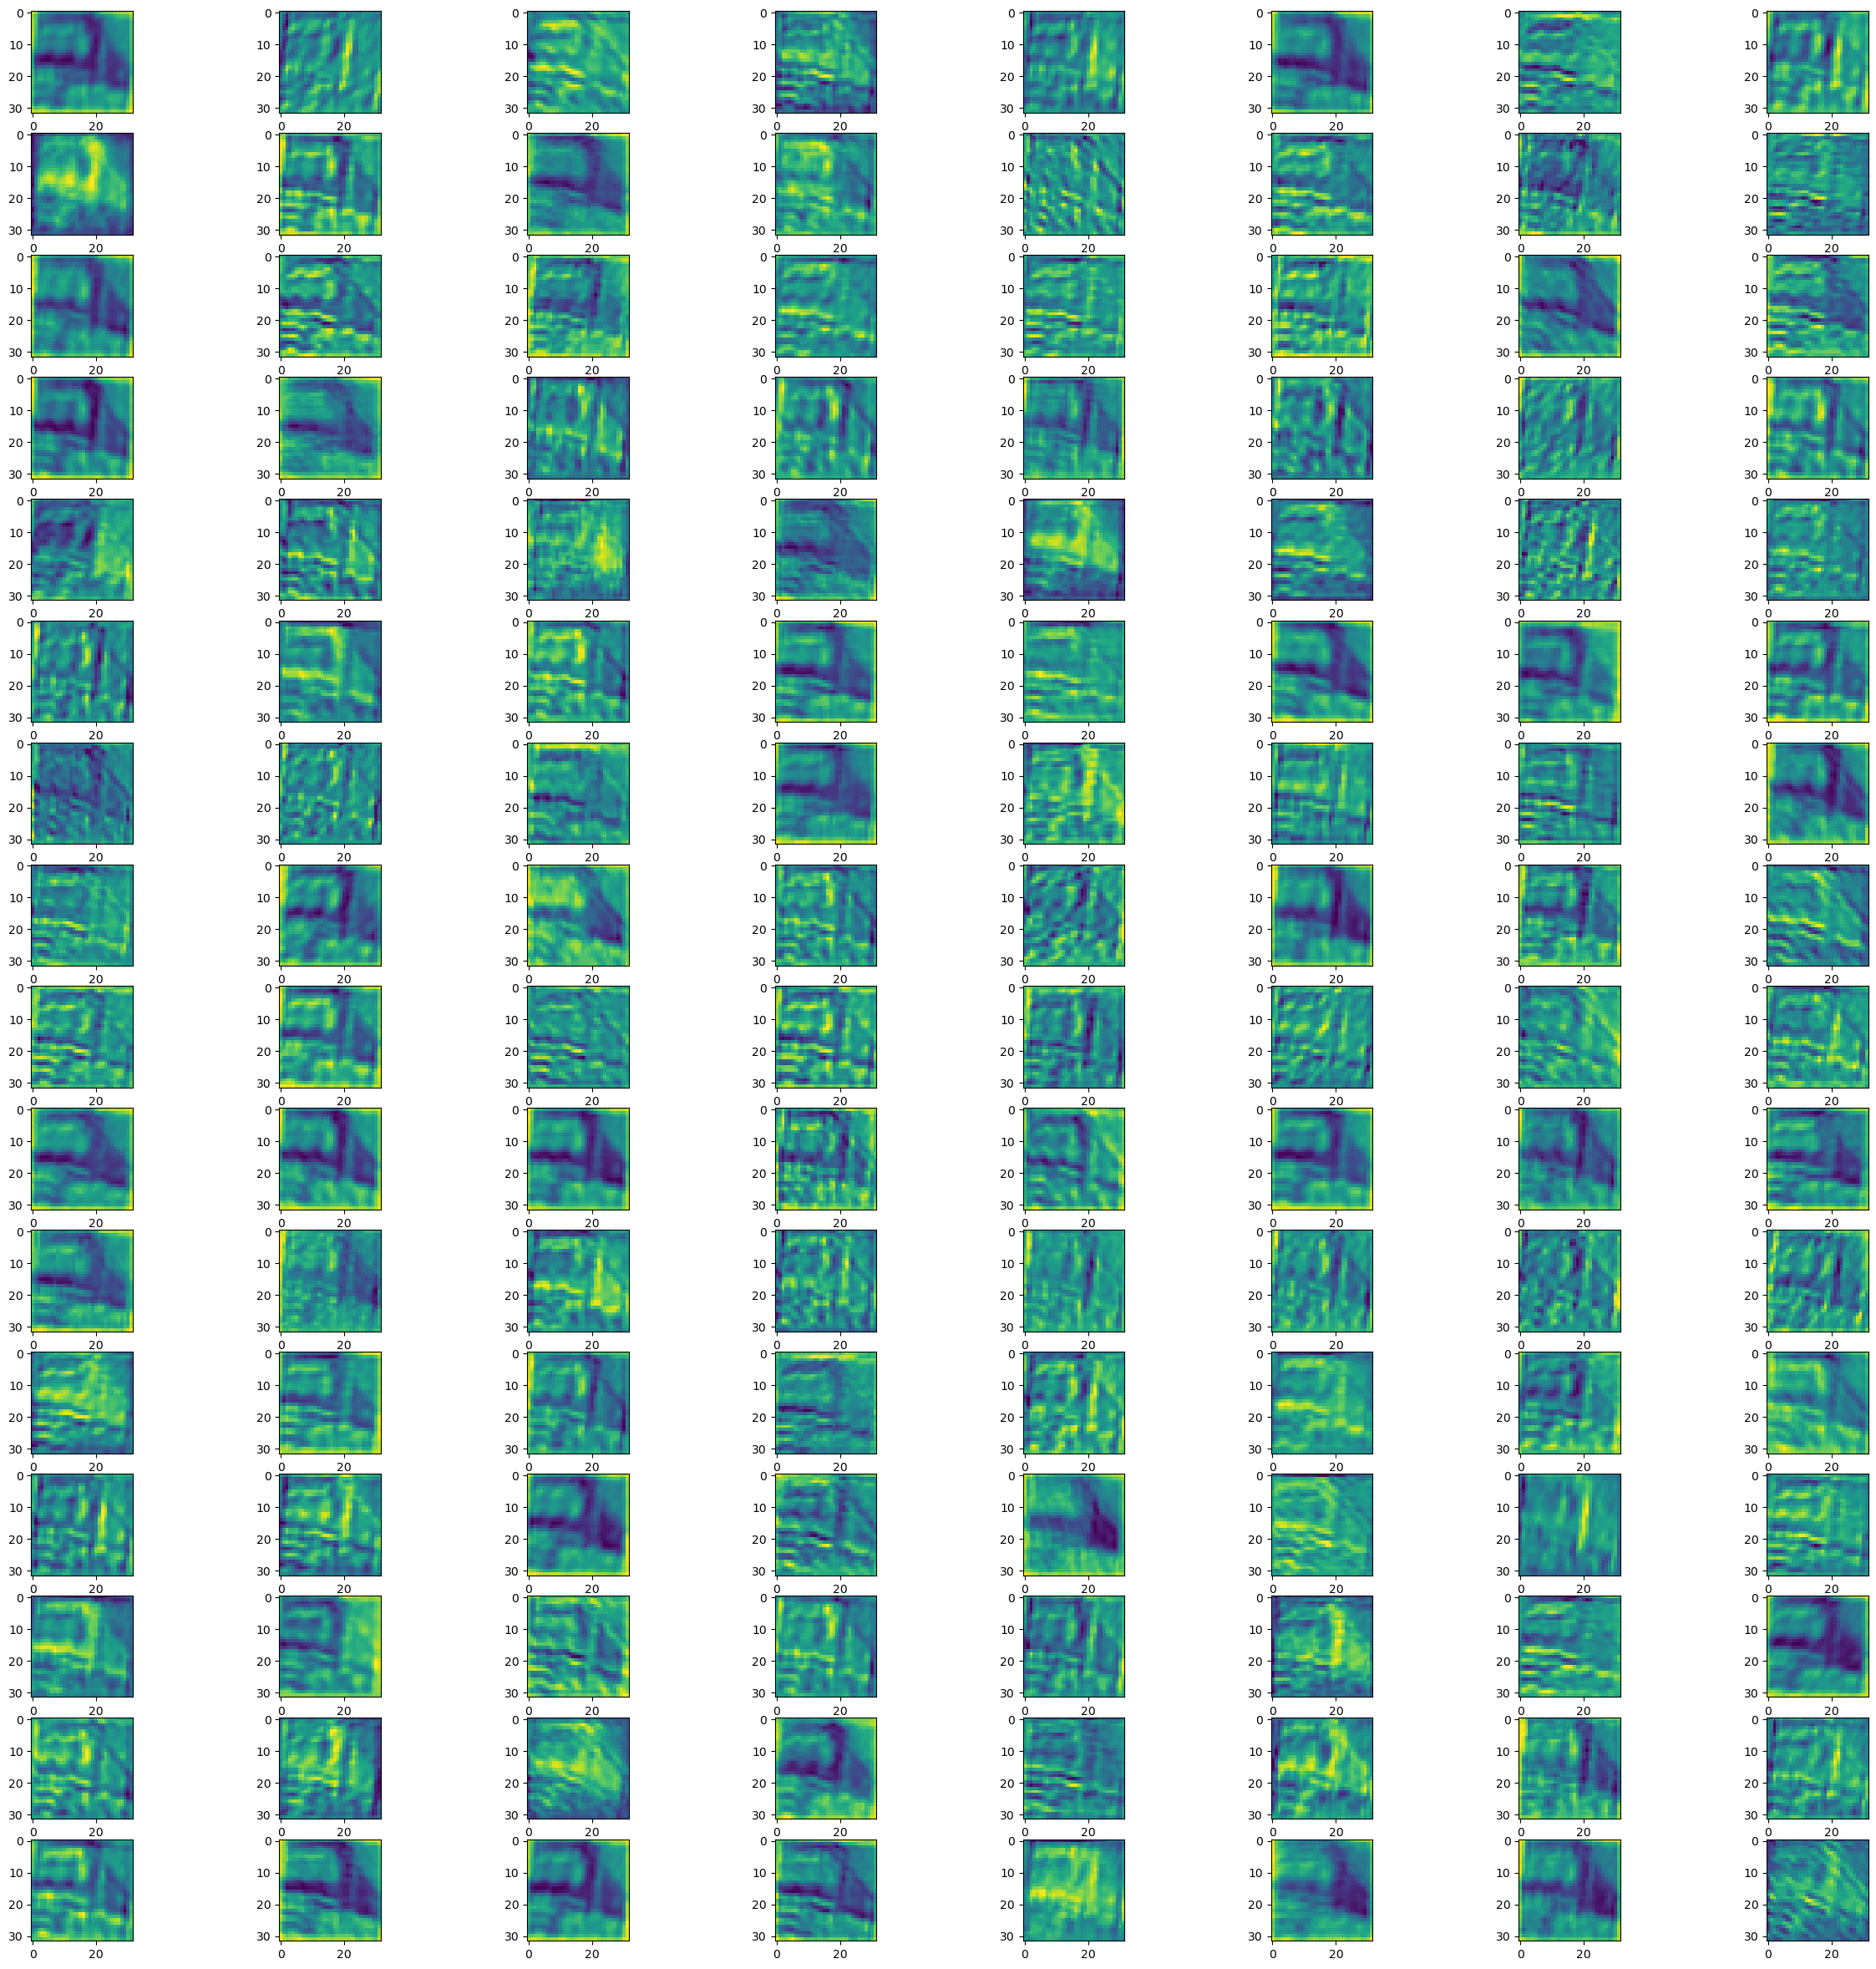

In [ ]:
image, label = train_dataset[1]
image = model.conv1(image.to(device))
with torch.no_grad():
    plt.figure(figsize=(15, 5))
    for i in range(32):
        plt.subplot(4, 8, i + 1)
        plt.imshow(image[i].cpu())
plt.show()

image, label = train_dataset[1]
image = model.conv3(model.conv2(model.conv1(image.to(device))))
with torch.no_grad():
    plt.figure(figsize=(30, 30))
    for i in range(128):
        plt.subplot(16, 8, i + 1)
        plt.imshow(image[i].cpu())
plt.show()